In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn xgboost catboost shap

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = pd.get_dummies(df, columns=['Sex', 'Embarked', 'Pclass'], drop_first=True)
X = df.drop('Survived', axis=1)
y = df['Survived']
print("Размер данных:", X.shape)
print("\nПервые строки после обработки:")
X.head()

Размер данных: (891, 9)

Первые строки после обработки:


,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Pclass_2,Pclass_3
0,22.0,1,0,7.2500,True,False,True,False,True
1,38.0,1,0,71.2833,False,False,False,False,False
2,26.0,0,0,7.9250,False,False,True,False,True
3,35.0,1,0,53.1000,False,False,True,False,False
4,35.0,0,0,8.0500,True,False,True,False,True


/tmp/ipykernel_2005/3389544355.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, palette='Set2')


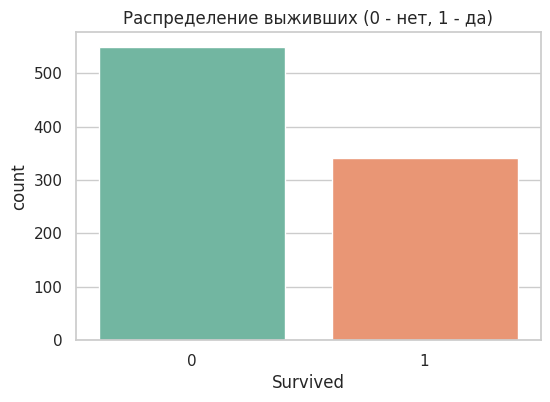

/tmp/ipykernel_2005/3389544355.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Sex_male', y='Survived', data=df, ci=None, palette='coolwarm')
/tmp/ipykernel_2005/3389544355.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex_male', y='Survived', data=df, ci=None, palette='coolwarm')


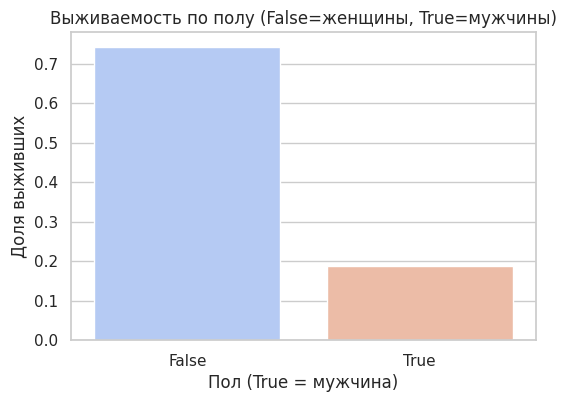

/tmp/ipykernel_2005/3389544355.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Pclass_3', y='Survived', data=df, ci=None, palette='viridis')
/tmp/ipykernel_2005/3389544355.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass_3', y='Survived', data=df, ci=None, palette='viridis')


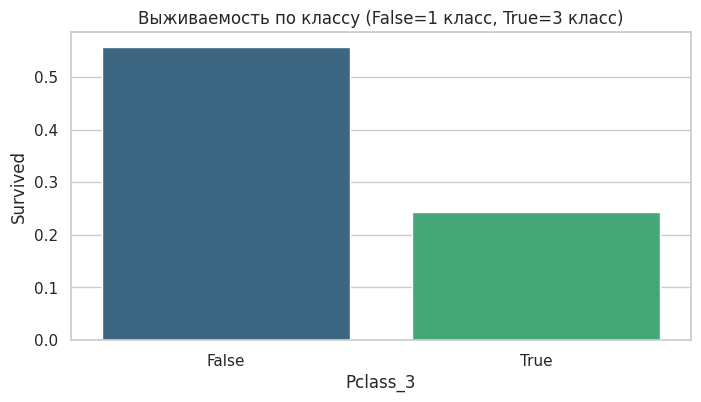

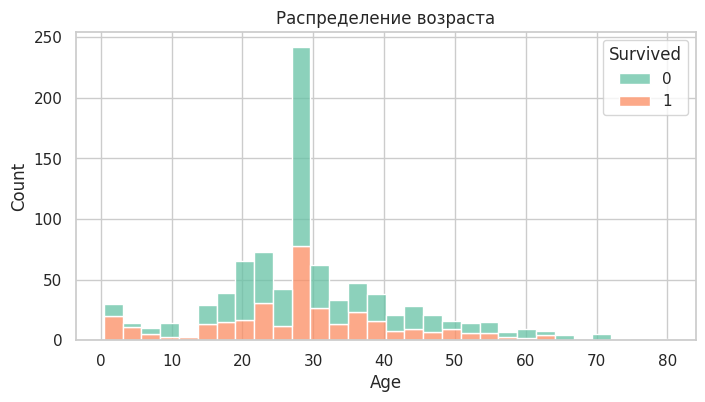

/tmp/ipykernel_2005/3389544355.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Survived', y='Fare', palette='Set2')


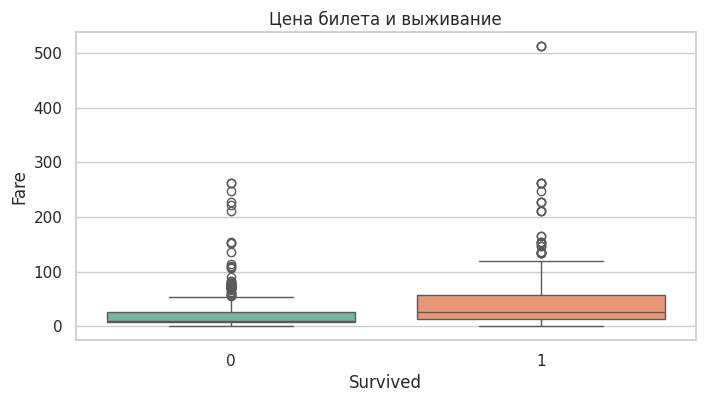

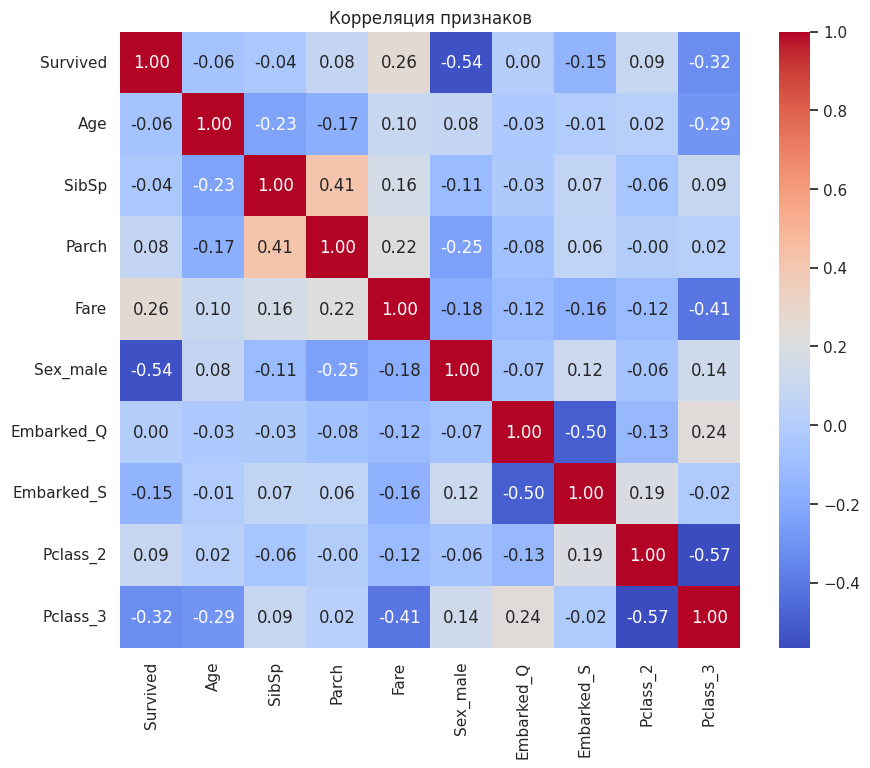

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))
sns.countplot(x='Survived', data=df, palette='Set2')
plt.title('Распределение выживших (0 - нет, 1 - да)')
plt.show()
plt.figure(figsize=(6, 4))
sns.barplot(x='Sex_male', y='Survived', data=df, ci=None, palette='coolwarm') #пол
plt.title('Выживаемость по полу (False=женщины, True=мужчины)')
plt.xlabel('Пол (True = мужчина)')
plt.ylabel('Доля выживших')
plt.show()
plt.figure(figsize=(8, 4))
sns.barplot(x='Pclass_3', y='Survived', data=df, ci=None, palette='viridis') #классы
plt.title('Выживаемость по классу (False=1 класс, True=3 класс)')
plt.show()
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack', palette='Set2')
plt.title('Распределение возраста')
plt.show()
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Survived', y='Fare', palette='Set2')
plt.title('Цена билета и выживание')
plt.show()
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Корреляция признаков')
plt.show()

Logistic Regression: Accuracy = 0.7989
Decision Tree: Accuracy = 0.7654
Random Forest: Accuracy = 0.8101
XGBoost: Accuracy = 0.8156
CatBoost: Accuracy = 0.8156
KNN: Accuracy = 0.8101


/tmp/ipykernel_2005/2224355987.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.values()), y=list(results.keys()), palette='viridis')


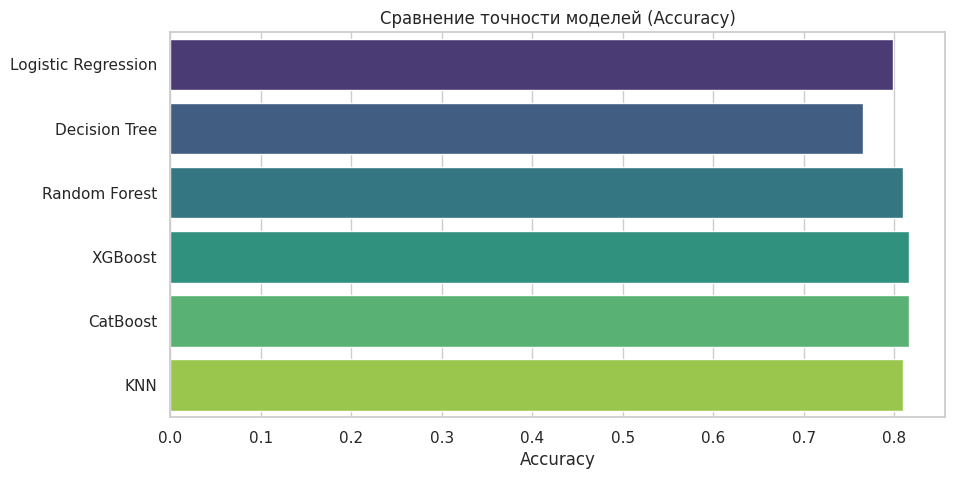

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# 1. Разделяем данные на обучение (80%) и тест (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Масштабирование (нужно для Linear Regression и KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Словарь моделей
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42),
    "KNN": KNeighborsClassifier()
}

# 4. Цикл обучения и оценки
results = {}
for name, model in models.items():
    # Деревьям и бустингам отдаем исходные данные, остальным — масштабированные
    if name in ["Decision Tree", "Random Forest", "XGBoost", "CatBoost"]:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"{name}: Accuracy = {acc:.4f}")

# 5. Визуализация результатов
plt.figure(figsize=(10, 5))
sns.barplot(x=list(results.values()), y=list(results.keys()), palette='viridis')
plt.title('Сравнение точности моделей (Accuracy)')
plt.xlabel('Accuracy')
plt.show()

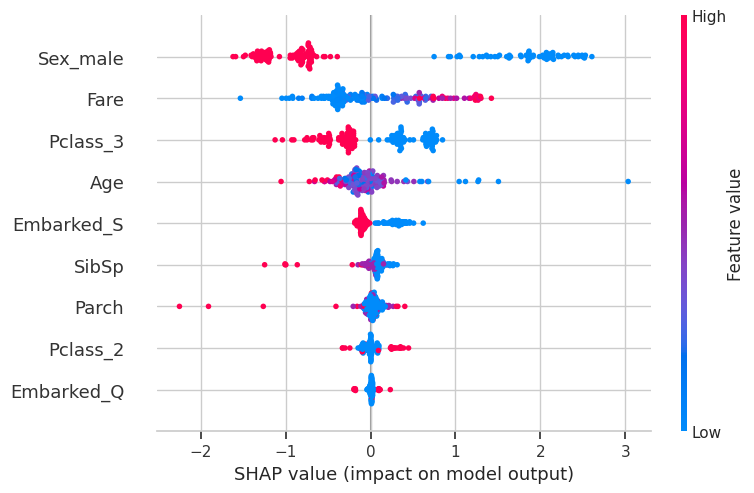

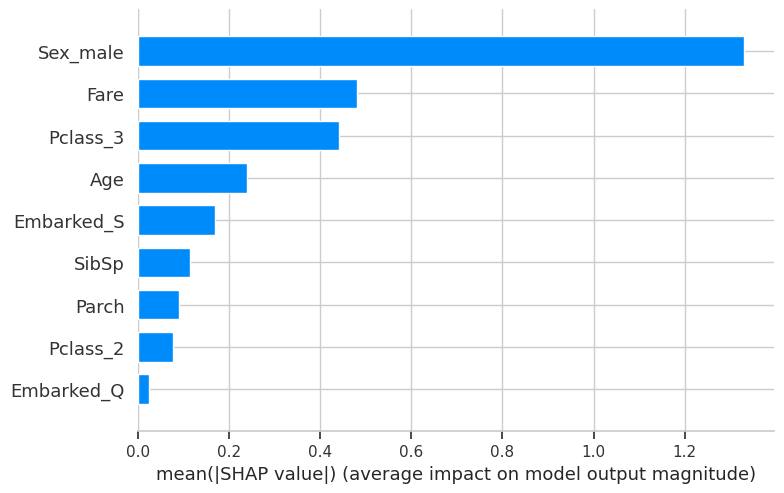

In [ ]:
import shap
best_model = models["CatBoost"]

# Инициализируем SHAP для деревьев
explainer = shap.TreeExplainer(best_model)

# Считаем SHAP-значения на тестовой выборке
shap_values = explainer.shap_values(X_test)

# 1. Summary plot (пчелиный рой) — показывает важность и направление влияния
plt.figure()
shap.summary_plot(shap_values, X_test, feature_names=X.columns)

# 2. Bar plot — просто ранжирование важности признаков
plt.figure()
shap.summary_plot(shap_values, X_test, feature_names=X.columns, plot_type="bar")
